# 01_cuDF / 03 — `cudf.pandas`: unchanged pandas code on the GPU

In notebooks 01 and 02 we wrote `cudf.` instead of `pd.`. **`cudf.pandas`** removes even that step: you keep writing normal pandas code, and it runs on the GPU wherever cuDF supports the operation.

How it works:
- After `%load_ext cudf.pandas`, `import pandas` gives you a **proxy** module. Every DataFrame/Series is a proxy object that holds either a cuDF (GPU) or a pandas (CPU) object.
- Each call is tried on the **GPU first**. If cuDF doesn't support it, the data is copied to the CPU and real pandas runs it (**fallback**). Your code never sees the difference, except in speed.

This notebook covers:
1. Turning it on
2. Plain pandas code running on the GPU
3. Seeing what ran where: the profilers
4. CPU fallback
5. Working with NumPy, matplotlib and other libraries
6. Benchmark: the same script with and without `cudf.pandas`
7. Other ways to enable it, and gotchas

> **Restart the kernel before running this notebook.** The extension must load *before* pandas is imported anywhere in the session.

## 1. Turn it on

In [1]:
%load_ext cudf.pandas

import pandas as pd      # <- now the GPU-accelerated proxy
import numpy as np

In [2]:
import cudf, cupy as cp, platform

props = cp.cuda.runtime.getDeviceProperties(0)
print(f"Python {platform.python_version()} | cuDF {cudf.__version__} | pandas {pd.__version__}")
print(f"GPU    {props['name'].decode()}")

Python 3.13.16 | cuDF 26.06.00 | pandas 2.2.3
GPU    Tesla T4


In [3]:
df = pd.DataFrame({"a": [1, 2, 3]})
# The proxy deliberately reports pandas' own class name, so isinstance() checks in your
# code and in other libraries keep working. The profilers in section 3 show where it really runs.
print(type(df))
print(isinstance(df, pd.DataFrame))

<class 'pandas.core.frame.DataFrame'>
True


## 2. Plain pandas code

Nothing below mentions cuDF. It is ordinary pandas.

In [4]:
N = 5_000_000
rng = np.random.default_rng(0)
cities = np.array(["Hyderabad", "Bengaluru", "Pune", "Jaipur", "Chennai", "Delhi", "Mumbai", "Kolkata"])

df = pd.DataFrame({
    "customer_id": rng.integers(0, 200_000, N),
    "store_id":    rng.integers(0, 50, N),
    "amount":      rng.random(N) * 500,
    "city":        cities[rng.integers(0, len(cities), N)],
    "ts":          pd.Timestamp("2026-01-01") + pd.to_timedelta(rng.integers(0, 180 * 86_400, N), unit="s"),
})
df.head()

,customer_id,store_id,amount,city,ts
0,170124,17,355.667483,Kolkata,2026-02-04 16:04:45
1,127392,0,238.213416,Jaipur,2026-03-31 07:08:09
2,102227,15,279.156574,Pune,2026-03-26 08:22:02
3,53957,49,445.768930,Bengaluru,2026-01-25 15:17:47
4,61565,45,401.038372,Chennai,2026-02-24 06:47:37


In [5]:
%%time
summary = (df[df["amount"] > 100]
           .groupby(["city", df["ts"].dt.month])["amount"]
           .agg(["sum", "mean", "count"])
           .sort_values("sum", ascending=False))
summary.head()

CPU times: user 186 ms, sys: 69.3 ms, total: 256 ms
Wall time: 251 ms


,,sum,mean,count
city,ts,,,
Hyderabad,5,2.603409e+07,300.458070,86648
Jaipur,1,2.597758e+07,300.003264,86591
Chennai,3,2.592719e+07,299.774429,86489
Delhi,5,2.590733e+07,300.409650,86240
Hyderabad,3,2.590577e+07,300.134061,86314


In [6]:
%%time
customers = pd.DataFrame({
    "customer_id": np.arange(200_000),
    "segment":     rng.choice(["Consumer", "Corporate", "Home Office"], 200_000),
})
joined = df.merge(customers, on="customer_id")
joined.groupby("segment")["amount"].sum()

CPU times: user 121 ms, sys: 20.2 ms, total: 141 ms
Wall time: 138 ms


,amount
segment,
Consumer,4.163669e+08
Corporate,4.151201e+08
Home Office,4.182964e+08


## 3. What ran where? The profilers

`%%cudf.pandas.profile` runs a cell and lists every pandas function it called, with time spent **on the GPU** and **on the CPU**. If something you expected to be fast shows up under CPU, that is a fallback.

In [7]:
%%cudf.pandas.profile
by_store = df.groupby("store_id")["amount"].mean()
top = df.nlargest(5, "amount")
upper = df["city"].str.upper()
reversed_names = df["city"].head(1000).apply(lambda s: s[::-1])   # arbitrary Python per value

                                                                                                                  
                                            Total time elapsed: 1.656 seconds                                     
                                          9 GPU function calls in 0.081 seconds                                   
                                          1 CPU function calls in 0.950 seconds                                   
                                                                                                                  
                                                          Stats                                                   
                                                                                                                  
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ Function                     ┃ GPU ncalls ┃ GPU cumtime ┃ GPU percall ┃ CPU ncalls ┃ CPU cumtime ┃ CPU percall ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ DataFrame.groupby            │ 1          │ 0.008       │ 0.008       │ 0          │ 0.000       │ 0.000       │
│ DataFrameGroupBy.__getitem__ │ 1          │ 0.004       │ 0.004       │ 0          │ 0.000       │ 0.000       │
│ GroupBy.mean                 │ 1          │ 0.018       │ 0.018       │ 0          │ 0.000       │ 0.000       │
│ DataFrame.nlargest           │ 1          │ 0.037       │ 0.037       │ 0          │ 0.000       │ 0.000       │
│ DataFrame.__getitem__        │ 2          │ 0.001       │ 0.001       │ 0          │ 0.000       │ 0.000       │
│ Series                       │ 1          │ 0.000       │ 0.000       │ 0          │ 0.000       │ 0.000       │
│ StringMethods.upper          │ 1          │ 0.011       │ 0.011       │ 0          │ 0.000       │ 0.000       │
│ NDFrame.head                 │ 1          │ 0.001       │ 0.001       │ 0          │ 0.000       │ 0.000       │
│ Series.apply                 │ 0          │ 0.000       │ 0.000       │ 1          │ 0.950       │ 0.950       │
└──────────────────────────────┴────────────┴─────────────┴─────────────┴────────────┴─────────────┴─────────────┘

Not all pandas operations ran on the GPU. The following functions required CPU fallback:

- Series.apply

To request GPU support for any of these functions, please file a Github issue here: 
]8;id=40928;https://github.com/rapidsai/cudf/issues/new?assignees=&labels=%3F+-+Needs+Triage%2C+feature+request&projects=&template=pandas_function_request.md&title=%5BFEA%5D\https://github.com/rapidsai/cudf/issues/new/choose]8;;\.

`%%cudf.pandas.line_profile` does the same per **line** of code, which is handy for longer cells.

In [8]:
%%cudf.pandas.line_profile
monthly = df.groupby(df["ts"].dt.month)["amount"].sum()
city_counts = df["city"].value_counts()
rolled = df.sort_values("ts")["amount"].rolling(1000).mean()

                                                                                                           
                                         Total time elapsed: 0.862 seconds                                 
                                                                                                           
                                                       Stats                                               
                                                                                                           
┏━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ Line no. ┃ Line                                                             ┃ GPU TIME(s) ┃ CPU TIME(s) ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ 1        │     monthly = df.groupby(df["ts"].dt.month)["amount"].sum()      │ 0.026663124 │             │
│          │                                                                  │             │             │
│ 2        │     city_counts = df["city"].value_counts()                      │ 0.030004168 │             │
│          │                                                                  │             │             │
│ 3        │     rolled = df.sort_values("ts")["amount"].rolling(1000).mean() │ 0.230145693 │             │
│          │                                                                  │             │             │
└──────────┴──────────────────────────────────────────────────────────────────┴─────────────┴─────────────┘

## 4. CPU fallback

When cuDF can't run an operation, `cudf.pandas` copies the data to host memory and lets pandas do it. The result is correct, but you pay for the copy (and pandas speed). A typical case is a Python function applied per element that cuDF can't compile for the GPU.

Fallbacks are fine for occasional or small steps. They hurt inside hot loops or on large data. Use the profiler to find them.

In [9]:
%%time
# Runs on the GPU
df["amount_rounded"] = df["amount"].round(1)

CPU times: user 5.66 ms, sys: 2.82 ms, total: 8.49 ms
Wall time: 13.2 ms


In [10]:
%%time
# Arbitrary Python returning strings: expect a CPU fallback (check with the profiler above)
df["city_code"] = df["city"].map(lambda s: s[:3].upper() + "-" + str(len(s)))
df[["city", "city_code"]].drop_duplicates().head()

CPU times: user 2.64 s, sys: 307 ms, total: 2.95 s
Wall time: 2.95 s


,city,city_code
0,Kolkata,KOL-7
1,Jaipur,JAI-6
2,Pune,PUN-4
3,Bengaluru,BEN-9
4,Chennai,CHE-7


## 5. Working with other libraries

Proxy objects behave like real pandas objects, so libraries that accept pandas also accept them.

Even NumPy results are wrapped: `to_numpy()` returns a proxy `ndarray` that acts like a normal NumPy array, and is converted to a real one when another library needs it.

In [11]:
arr = df["amount"].to_numpy()
print(type(arr), arr.shape)

<class 'cudf.pandas._wrappers.numpy.ndarray'> (5000000,)


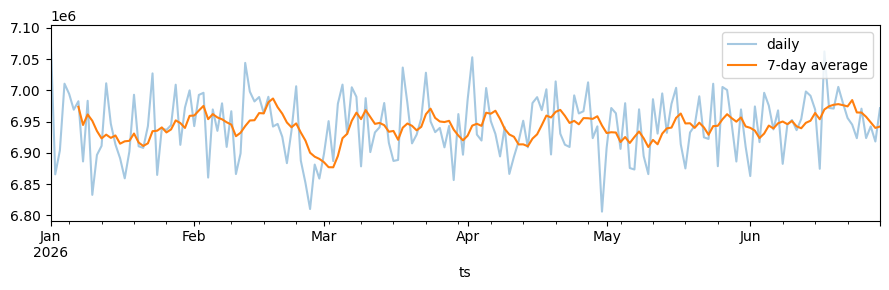

In [12]:
import matplotlib.pyplot as plt

daily = df.groupby(df["ts"].dt.floor("D"))["amount"].sum()
ax = daily.plot(figsize=(9, 3), alpha=0.4, label="daily")
daily.rolling(7).mean().plot(ax=ax, label="7-day average")
ax.legend(); plt.tight_layout(); plt.show()

## 6. Benchmark: same script, with and without `cudf.pandas`

A fair comparison needs two separate Python processes, because once the extension is loaded, all pandas in this kernel is accelerated. We write one pandas-only script and run it twice:

- `python workload.py` — plain pandas on the CPU
- `python -m cudf.pandas workload.py` — the same file, accelerated

The script times each step and also the whole run (including startup and GPU initialization), so we see the real end-to-end gain.

In [13]:
%%writefile workload.py
import json, sys, time
import numpy as np
import pandas as pd

N = int(sys.argv[1]) if len(sys.argv) > 1 else 5_000_000
rng = np.random.default_rng(0)
t = {}

def timed(name, fn):
    t0 = time.perf_counter()
    out = fn()
    t[name] = time.perf_counter() - t0
    return out

cities = np.array(["Hyderabad", "Bengaluru", "Pune", "Jaipur", "Chennai", "Delhi", "Mumbai", "Kolkata"])
df = timed("create DataFrame", lambda: pd.DataFrame({
    "customer_id": rng.integers(0, 200_000, N),
    "store_id":    rng.integers(0, 50, N),
    "amount":      rng.random(N) * 500,
    "city":        cities[rng.integers(0, len(cities), N)],
    "ts":          pd.Timestamp("2026-01-01") + pd.to_timedelta(rng.integers(0, 180 * 86_400, N), unit="s"),
}))
customers = pd.DataFrame({"customer_id": np.arange(200_000),
                          "segment": rng.choice(["Consumer", "Corporate", "Home Office"], 200_000)})

timed("groupby multi-agg", lambda: df.groupby("store_id").agg({"amount": ["sum", "mean"], "customer_id": "nunique"}))
timed("merge 5M x 200k",   lambda: df.merge(customers, on="customer_id"))
timed("sort 2 keys",       lambda: df.sort_values(["store_id", "amount"]))
timed("str.contains",      lambda: df[df["city"].str.contains("pur|bad", regex=True)])
timed("datetime groupby",  lambda: df.groupby(df["ts"].dt.month)["amount"].sum())
timed("value_counts",      lambda: df["city"].value_counts())
timed("groupby cumsum",    lambda: df.groupby("store_id")["amount"].cumsum())

print("RESULTS " + json.dumps(t))

Writing workload.py


In [14]:
import subprocess, sys, json, time

def run_workload(accelerated, n=N):
    cmd = [sys.executable] + (["-m", "cudf.pandas"] if accelerated else []) + ["workload.py", str(n)]
    t0 = time.perf_counter()
    proc = subprocess.run(cmd, capture_output=True, text=True)
    wall = time.perf_counter() - t0
    if proc.returncode != 0:
        print(proc.stderr[-3000:])
        raise RuntimeError(f"workload failed: {' '.join(cmd)}")
    line = next(l for l in proc.stdout.splitlines() if l.startswith("RESULTS "))
    res = json.loads(line[len("RESULTS "):])
    res["whole script (wall)"] = wall
    return res

cpu = run_workload(accelerated=False)
gpu = run_workload(accelerated=True)

bench = pd.DataFrame({"pandas (CPU)": cpu, "cudf.pandas (GPU)": gpu})
bench["speedup"] = bench["pandas (CPU)"] / bench["cudf.pandas (GPU)"]
bench.round(3)

,pandas (CPU),cudf.pandas (GPU),speedup
create DataFrame,1.257,1.593,0.789
groupby multi-agg,0.770,0.269,2.867
merge 5M x 200k,0.908,0.077,11.863
sort 2 keys,4.800,0.199,24.124
str.contains,2.041,0.022,93.128
datetime groupby,0.290,0.049,5.870
value_counts,0.545,0.024,22.794
groupby cumsum,0.106,0.053,2.003
whole script (wall),11.571,6.518,1.775


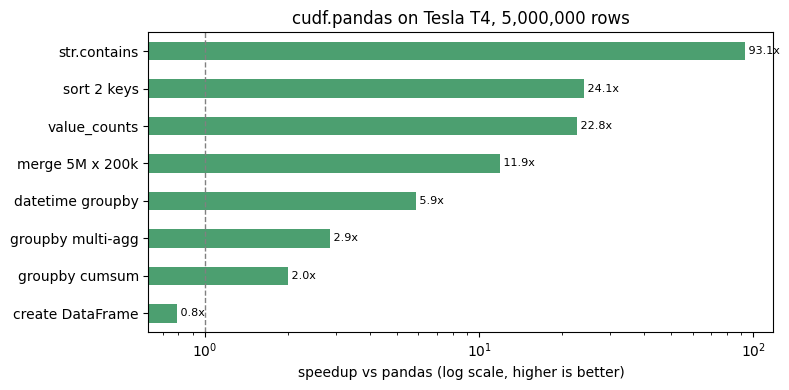

Whole script: 11.6 s -> 6.5 s  (1.8x)


In [15]:
plot_df = bench.drop(index="whole script (wall)").sort_values("speedup")
ax = plot_df["speedup"].plot.barh(figsize=(8, 4), color="#4C9F70")
ax.axvline(1, color="gray", lw=1, ls="--")
ax.set_xscale("log")
ax.set_xlabel("speedup vs pandas (log scale, higher is better)")
ax.set_title(f"cudf.pandas on {props['name'].decode()}, {N:,} rows")
for i, v in enumerate(plot_df["speedup"]):
    ax.text(v, i, f" {v:.1f}x", va="center", fontsize=8)
plt.tight_layout(); plt.show()

w = bench.loc["whole script (wall)"]
print(f"Whole script: {w['pandas (CPU)']:.1f} s -> {w['cudf.pandas (GPU)']:.1f} s  ({w['speedup']:.1f}x)")

Notes on the numbers:
- **create DataFrame** is often *slower* with `cudf.pandas`: the data is generated by NumPy on the CPU and then copied to the GPU. Loading straight from Parquet/CSV avoids this.
- The **whole script** time includes Python start-up and CUDA initialization (a second or two), so very small workloads may not benefit at all.
- The speedups here are lower than the native cuDF numbers from notebook 02 because of proxy overhead and copies. In exchange, you changed zero lines of code.

## 7. Other ways to enable it, and gotchas

| Where | How |
|---|---|
| Jupyter / Colab | `%load_ext cudf.pandas` in the first cell, before `import pandas` |
| Run a script | `python -m cudf.pandas my_script.py` |
| Inside a script | `import cudf.pandas; cudf.pandas.install()` at the very top, then `import pandas as pd` |

**Gotchas**
- It must be loaded **before** pandas is imported. If pandas was already imported, restart the kernel.
- Fallbacks are silent. Profile anything performance-critical.
- Results can differ slightly from pandas: floating-point sums may differ in the last digits, and the order of rows from unsorted `groupby` or `merge` may differ. Sort when order matters.
- GPU memory is still the limit. A 16 GB T4 fits roughly 5–8 GB of working data comfortably.

In [16]:
import os, gc
del df, joined, customers
gc.collect()
if os.path.exists("workload.py"):
    os.remove("workload.py")
free_b, total_b = cp.cuda.runtime.memGetInfo()
print(f"GPU memory used: {(total_b - free_b) / 1e9:.2f} GB / {total_b / 1e9:.1f} GB")

GPU memory used: 4.85 GB / 15.6 GB


## Summary

- `%load_ext cudf.pandas` (or `python -m cudf.pandas`) accelerates existing pandas code with **no changes**.
- Each operation runs on the GPU if possible and **falls back to pandas on the CPU** otherwise.
- `%%cudf.pandas.profile` and `%%cudf.pandas.line_profile` show what ran where.
- Native cuDF (notebook 02) is faster still, but `cudf.pandas` is the quickest way to speed up code you already have.

**Next:** `04_benchmark_cudf_vs_pandas.ipynb` — a careful benchmark of pandas, `cudf.pandas` and native cuDF across data sizes.